
## TODAY:

- Part A: We will divide our documents into CHUNKS
- Part B: We will encode our CHUNKS into VECTORS and put in Chroma
- Part C: We will visualize our vectors

# PART A: Divide our documents into chunks

How many characters in all the documents?

In [1]:
import glob  # 파일 경로 패턴 매칭을 위한 모듈

# 모든 문서의 총 글자 수를 계산합니다

# 지식 베이스 경로 패턴 설정 (하위 폴더 포함 모든 .md 파일)
knowledge_base_path = "knowledge-base/**/*.md"

# 패턴에 맞는 모든 파일 경로를 재귀적으로 검색
files = glob.glob(knowledge_base_path, recursive=True)
print(f"지식 베이스에서 {len(files)}개의 파일을 찾았습니다")

# 전체 내용을 담을 빈 문자열 초기화
entire_knowledge_base = ""

# 각 파일을 순서대로 읽어서 하나의 문자열로 합치기
for file_path in files:
    with open(file_path, 'r', encoding='utf-8') as f:  # UTF-8 인코딩으로 파일 열기
        entire_knowledge_base += f.read()       # 파일 내용 추가
        entire_knowledge_base += "\n\n"         # 파일 사이에 빈 줄 2개 삽입

# 전체 글자 수 출력 (천 단위 구분자 포함)
print(f"지식 베이스 총 글자 수: {len(entire_knowledge_base):,}")

지식 베이스에서 76개의 파일을 찾았습니다
지식 베이스 총 글자 수: 304,434


How many tokens in all the documents?

프롬프트에 넣고 사용하려면 이 정도의 토큰을 매번 사용하야한다. 비용 문제

In [2]:
# How many tokens in all the documents?
import tiktoken
# price is a factor for our company, so we're going to use a low cost model
MODEL = "gpt-4.1-nano"

encoding = tiktoken.encoding_for_model(MODEL)
tokens = encoding.encode(entire_knowledge_base)
token_count = len(tokens)
print(f"Total tokens for {MODEL}: {token_count:,}")

Total tokens for gpt-4.1-nano: 63,555


Load in everything in the knowledgebase using LangChain's loaders

In [3]:
# LangChain의 로더를 사용하여 지식 베이스의 모든 파일을 불러옵니다
import glob
import os

# 지식 베이스 내 모든 하위 폴더 경로 목록 가져오기
folders = glob.glob("knowledge-base/*")

# LangChain의 문서 로더 임포트
from langchain_community.document_loaders import DirectoryLoader, TextLoader

# 불러온 문서를 저장할 빈 리스트 초기화
documents = []

# 각 폴더를 순회하며 문서 로드
for folder in folders:
    # 폴더명을 문서 타입으로 사용 (예: "products", "faqs" 등)
    doc_type = os.path.basename(folder)

    # 해당 폴더 내 모든 .md 파일을 UTF-8 인코딩으로 불러오는 로더 생성
    loader = DirectoryLoader(
        folder,                          # 탐색할 폴더 경로
        glob="**/*.md",                  # 하위 폴더 포함 모든 .md 파일 대상
        loader_cls=TextLoader,           # 텍스트 파일 로더 사용
        loader_kwargs={'encoding': 'utf-8'}  # UTF-8 인코딩 지정
    )

    # 폴더 내 문서 로드
    folder_docs = loader.load()

    # 각 문서에 메타데이터(문서 타입) 추가 후 전체 리스트에 저장
    for doc in folder_docs:
        doc.metadata["doc_type"] = doc_type  # 어느 폴더 출처인지 태그 추가
        documents.append(doc)

# 총 로드된 문서 수 출력
print(f"총 {len(documents)}개의 문서를 불러왔습니다")

총 76개의 문서를 불러왔습니다


In [4]:
documents[1]

Document(metadata={'source': 'knowledge-base\\company\\careers.md', 'doc_type': 'company'}, page_content="# Careers at Insurellm\n\n## Why Join Insurellm?\n\nAt Insurellm, we're not just building software—we're revolutionizing an entire industry. Since our founding in 2015, we've evolved from a high-growth startup to a lean, profitable company with 32 highly talented employees managing 32 active contracts across all eight of our product lines.\n\nAfter reaching 200 employees in 2020, we strategically restructured in 2022-2023 to focus on sustainable growth, operational excellence, and building a world-class remote-first culture. Today, we're a tight-knit team of exceptional professionals who deliver outsized impact through automation, AI, and strategic focus on high-value enterprise clients—from regional insurers to global reinsurance partners.\n\n### Our Culture\n\nWe live by our core values every day:\n- **Innovation First**: We encourage experimentation and creative problem-solving\

Divide into chunks using the RecursiveCharacterTextSplitter

In [5]:
# RecursiveCharacterTextSplitter를 사용하여 문서를 청크(조각)로 분할합니다
from langchain_text_splitters import RecursiveCharacterTextSplitter

# 텍스트 분할기 설정
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,    # 각 청크의 최대 글자 수
    chunk_overlap=200   # 인접한 청크 간 겹치는 글자 수 (문맥 유지용)
)

# 불러온 문서들을 청크로 분할
chunks = text_splitter.split_documents(documents)

# 결과 출력
print(f"총 {len(chunks)}개의 청크로 분할되었습니다")
print(f"첫 번째 청크:\n\n{chunks[0]}")

총 413개의 청크로 분할되었습니다
첫 번째 청크:

page_content='# About Insurellm

Insurellm was founded by Avery Lancaster in 2015 as an insurance tech startup designed to disrupt an industry in need of innovative products. Its first product was Markellm, the marketplace connecting consumers with insurance providers.

The company experienced rapid growth in its first five years, expanding its product portfolio to include Carllm (auto insurance portal), Homellm (home insurance portal), and Rellm (enterprise reinsurance platform). By 2020, Insurellm had reached a peak of 200 employees with 12 offices across the US.' metadata={'source': 'knowledge-base\\company\\about.md', 'doc_type': 'company'}


In [6]:
chunks[100]

Document(metadata={'source': 'knowledge-base\\contracts\\Contract with GlobalRe Partners for Rellm.md', 'doc_type': 'contracts'}, page_content='13. **Climate Risk Analytics:** Forward-looking climate modeling:\n    - IPCC climate scenario analysis (RCP 2.6, 4.5, 8.5)\n    - Transition risk assessment\n    - Physical risk modeling for perils (hurricane, wildfire, flood, drought)\n    - Sea level rise impact analysis\n    - Temperature trend incorporation\n    - Climate-adjusted pricing recommendations\n    - Stranded asset identification\n    - Green reinsurance opportunities\n\n---\n\n## Support\n\nInsurellm commits to comprehensive Enterprise-level support for GlobalRe Partners:\n\n1. **Dedicated Success Team:**\n   - Executive sponsor (CEO-level) with quarterly strategic reviews\n   - Dedicated Senior Vice President of Customer Success with bi-weekly engagement\n   - Technical Account Manager for platform optimization\n   - Solutions Architect team (2 FTE) for strategic initiatives\n

# PART B: OpenAIEmbeddings Make vectors and store in Chroma


At this point, you might want to add it to your `.env` file and run `load_dotenv(override=True)`

(This actually shouldn't be required).

embedding 모델을 바꾸면 시각화가 다르다
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
There are 413 vectors with 384 dimensions in the vector store

embeddings = OpenAIEmbeddings(model="text-embedding-3-large")
There are 413 vectors with 3,072 dimensions in the vector store

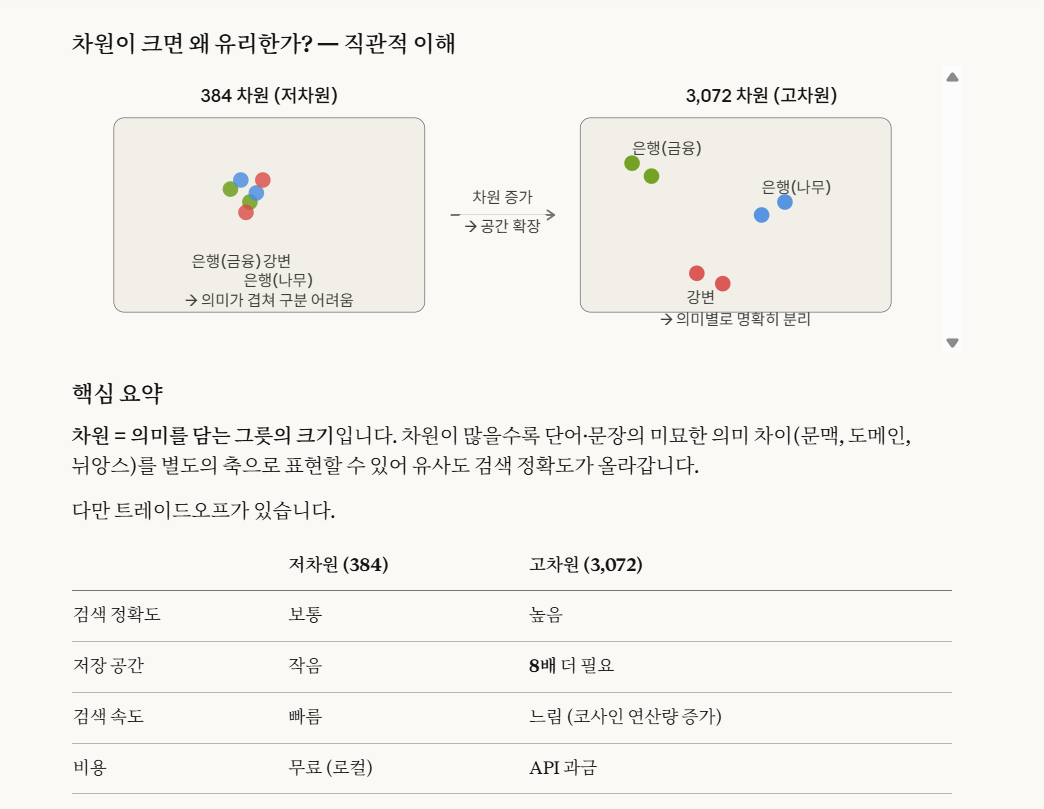

In [7]:
# price is a factor for our company, so we're going to use a low cost model
from dotenv import load_dotenv



load_dotenv(override=True)
openai_api_key = os.getenv('OPENAI_API_KEY')
if openai_api_key:
    print(f"OpenAI API Key exists and begins {openai_api_key[:8]}")
else:
    print("OpenAI API Key not set")

OpenAI API Key exists and begins sk-proj-


In [8]:
# 임베딩 모델 선택 및 벡터 데이터베이스 생성
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
import os

MODEL = "gpt-4.1-nano"
embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

# 벡터 DB 저장 폴더명 지정
db_name = "vector_db_OpenAI"

# 기존 벡터 DB가 있으면 삭제 후 새로 생성 (중복 방지)
if os.path.exists(db_name):
    Chroma(persist_directory=db_name, embedding_function=embeddings).delete_collection()

# 청크를 임베딩으로 변환하여 벡터 DB 생성 및 디스크에 저장
vectorstore = Chroma.from_documents(
    documents=chunks,          # 분할된 문서 청크
    embedding=embeddings,      # 사용할 임베딩 모델
    persist_directory=db_name  # 저장할 폴더 경로
)

# 저장된 문서 수 확인 출력
print(f"벡터 DB 생성 완료: {vectorstore._collection.count()}개의 문서 저장됨")

벡터 DB 생성 완료: 413개의 문서 저장됨


Let's investigate the vectors

In [9]:
# 벡터 저장소의 내부 구조를 확인합니다
collection = vectorstore._collection  # Chroma 내부 컬렉션 객체 접근

# 저장된 전체 벡터 수 조회
count = collection.count()

# 샘플 벡터 1개를 가져와 차원 수 확인
sample_embedding = collection.get(
    limit=1,                    # 1개만 조회
    include=["embeddings"]      # 임베딩 벡터값 포함하여 반환
)["embeddings"][0]              # 반환된 딕셔너리에서 첫 번째 임베딩 추출

# 벡터의 차원 수 계산 (= 숫자 배열의 길이)
dimensions = len(sample_embedding)

# 결과 출력
print(f"벡터 저장소에 {count:,}개의 벡터가 있으며, 각 벡터는 {dimensions:,}차원입니다")

벡터 저장소에 413개의 벡터가 있으며, 각 벡터는 3,072차원입니다


# Part C: Visualize!

Prework

In [10]:
# 시각화를 위한 사전 준비 작업
import numpy as np  # 수치 연산 라이브러리

# 벡터 저장소에서 임베딩, 문서 내용, 메타데이터를 한번에 가져오기
result = collection.get(include=['embeddings', 'documents', 'metadatas'])

# 임베딩 리스트를 numpy 배열로 변환 (수치 연산 및 시각화에 용이)
vectors = np.array(result['embeddings'])   # shape: (문서수, 384)

# 문서 텍스트 내용 추출
documents = result['documents']

# 문서별 메타데이터 추출 (doc_type 등 포함)
metadatas = result['metadatas']

# 각 문서의 doc_type 추출 (예: 'products', 'employees' 등)
doc_types = [metadata['doc_type'] for metadata in metadatas]

# doc_type에 따라 시각화용 색상 지정
# products → 파랑, employees → 초록, contracts → 빨강, company → 주황
colors = [
    ['blue', 'green', 'red', 'orange'][          # 색상 목록
    ['products', 'employees', 'contracts', 'company'].index(t)]  # doc_type의 인덱스로 색상 선택
    for t in doc_types                           # 모든 문서에 대해 반복
]

In [11]:
vectors

array([[-1.33285522e-02,  3.39050293e-02, -2.12554932e-02, ...,
        -7.11441040e-03,  2.68173218e-03,  2.18272209e-04],
       [ 2.04772949e-02,  3.06701660e-02, -2.31170654e-02, ...,
         1.44042969e-02, -3.14116478e-05, -7.32803345e-03],
       [ 3.99475098e-02,  4.60510254e-02, -2.49786377e-02, ...,
         6.94656372e-03,  1.07574463e-02, -1.40228271e-02],
       ...,
       [-3.57360840e-02,  7.81250000e-03, -2.52532959e-02, ...,
        -2.00195312e-02,  4.42504883e-02,  4.33731079e-03],
       [-2.15148926e-02,  7.96508789e-03, -3.04260254e-02, ...,
        -2.04620361e-02,  2.09655762e-02,  1.11846924e-02],
       [-1.16653442e-02,  3.13186646e-03, -2.44903564e-02, ...,
        -1.81732178e-02,  1.24130249e-02,  5.97000122e-03]],
      shape=(413, 3072))

In [12]:
# 사람이 이해하기 쉽도록 고차원 벡터를 2D로 시각화합니다
# t-SNE(t-분산 확률적 이웃 임베딩) 알고리즘으로 차원 축소
from sklearn.manifold import TSNE
import plotly.graph_objects as go

# t-SNE로 384차원 벡터 → 2차원으로 축소
tsne = TSNE(
    n_components=2,   # 축소할 목표 차원 수 (2D)
    random_state=42   # 재현 가능한 결과를 위한 랜덤 시드 고정
)
reduced_vectors = tsne.fit_transform(vectors)  # 실제 차원 축소 실행

# 2D 산점도 생성
fig = go.Figure(data=[go.Scatter(
    x=reduced_vectors[:, 0],    # 축소된 x좌표
    y=reduced_vectors[:, 1],    # 축소된 y좌표
    mode='markers',             # 점(marker)으로 표시
    marker=dict(
        size=5,                 # 점 크기
        color=colors,           # doc_type별 색상 적용
        opacity=0.8             # 점 투명도
    ),
    # 마우스 호버 시 표시할 텍스트 (문서 타입 + 앞 100글자 미리보기)
    text=[f"Type: {t}<br>Text: {d[:100]}..." for t, d in zip(doc_types, documents)],
    hoverinfo='text'            # 호버 시 text만 표시
)])

# 그래프 레이아웃 설정
fig.update_layout(
    title='2D Chroma 벡터 저장소 시각화',
    scene=dict(
        xaxis_title='x',        # x축 레이블
        yaxis_title='y'         # y축 레이블
    ),
    width=800,                  # 그래프 너비 (px)
    height=600,                 # 그래프 높이 (px)
    margin=dict(r=20, b=10, l=10, t=40)  # 여백 설정 (우, 하, 좌, 상)
)

fig.show()  # 그래프 출력

In [13]:
# 이번엔 3D로 시각화해봅니다!

# t-SNE로 384차원 벡터 → 3차원으로 축소
tsne = TSNE(
    n_components=3,   # 축소할 목표 차원 수 (3D)
    random_state=42   # 랜덤 시드 고정 (재현 가능한 결과)
)
reduced_vectors = tsne.fit_transform(vectors)  # 실제 차원 축소 실행

# 3D 산점도 생성
fig = go.Figure(data=[go.Scatter3d(
    x=reduced_vectors[:, 0],    # 축소된 x좌표
    y=reduced_vectors[:, 1],    # 축소된 y좌표
    z=reduced_vectors[:, 2],    # 축소된 z좌표 (3D에서 추가된 축)
    mode='markers',             # 점(marker)으로 표시
    marker=dict(
        size=5,                 # 점 크기
        color=colors,           # doc_type별 색상 적용
        opacity=0.8             # 점 투명도
    ),
    # 마우스 호버 시 문서 타입 + 내용 앞 100글자 표시
    text=[f"Type: {t}<br>Text: {d[:100]}..." for t, d in zip(doc_types, documents)],
    hoverinfo='text'
)])

# 그래프 레이아웃 설정
fig.update_layout(
    title='3D Chroma 벡터 저장소 시각화',
    scene=dict(
        xaxis_title='x',        # x축 레이블
        yaxis_title='y',        # y축 레이블
        zaxis_title='z'         # z축 레이블 (3D 추가)
    ),
    width=900,                  # 그래프 너비 (2D보다 약간 크게)
    height=700,                 # 그래프 높이 (2D보다 약간 크게)
    margin=dict(r=10, b=10, l=10, t=40)  # 여백 설정
)

fig.show()  # 그래프 출력